In [46]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [47]:
import os

os.listdir()

['.config', 'credit_risk.db', 'archive (8).zip', 'sample_data']

In [48]:
import os

print(os.path.getsize("archive (8).zip"))

5408940


In [49]:
!file "archive (8).zip"

archive (8).zip: Zip archive data, at least v4.5 to extract, compression method=deflate


In [50]:
import zipfile

print(zipfile.is_zipfile("archive (8).zip"))

True


In [51]:
from zipfile import ZipFile

with ZipFile("archive (8).zip", "r") as zip_ref:
    zip_ref.extractall()

df = pd.read_csv("cs-training.csv")

In [52]:
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [54]:
df.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [55]:
df.shape

(150000, 12)

In [56]:
df.columns

Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')

In [57]:
df.rename(columns={
    "SeriousDlqin2yrs":"Default",
    "RevolvingUtilizationOfUnsecuredLines":"Credit_Utilization",
    "NumberOfTime30-59DaysPastDueNotWorse":"Late30_59",
    "DebtRatio":"Debt_Ratio",
    "MonthlyIncome":"Monthly_Income",
    "NumberOfOpenCreditLinesAndLoans":"Open_Credit_Lines",
    "NumberOfTimes90DaysLate":"Late90",
    "NumberRealEstateLoansOrLines":"RealEstate_Loans",
    "NumberOfTime60-89DaysPastDueNotWorse":"Late60_89",
    "NumberOfDependents":"Dependents"
}, inplace=True)

In [58]:
df.isnull().sum()

,0
Unnamed: 0,0
Default,0
Credit_Utilization,0
age,0
Late30_59,0
Debt_Ratio,0
Monthly_Income,29731
Open_Credit_Lines,0
Late90,0
RealEstate_Loans,0


In [59]:
df["Monthly_Income"] = df["Monthly_Income"].fillna(df["Monthly_Income"].median())

df["Dependents"] = df["Dependents"].fillna(df["Dependents"].median())

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df = df.drop_duplicates()

In [62]:
df["Default"].value_counts()

,count
Default,
0,139974
1,10026


In [63]:
df["Default"].value_counts(normalize=True)*100

,proportion
Default,
0,93.316
1,6.684


In [64]:
df["Default"].value_counts(normalize=True)*100

,proportion
Default,
0,93.316
1,6.684


In [65]:
df.isnull().sum()

,0
Unnamed: 0,0
Default,0
Credit_Utilization,0
age,0
Late30_59,0
Debt_Ratio,0
Monthly_Income,0
Open_Credit_Lines,0
Late90,0
RealEstate_Loans,0


In [66]:
df.to_csv("credit_risk_cleaned.csv", index=False)

In [67]:
df.drop("Unnamed: 0", axis=1, inplace=True)

In [68]:
df["Monthly_Income"] = df["Monthly_Income"].fillna(df["Monthly_Income"].median())

df["Dependents"] = df["Dependents"].fillna(df["Dependents"].median())

In [69]:
df.isnull().sum()

,0
Default,0
Credit_Utilization,0
age,0
Late30_59,0
Debt_Ratio,0
Monthly_Income,0
Open_Credit_Lines,0
Late90,0
RealEstate_Loans,0
Late60_89,0


In [70]:
df.duplicated().sum()

np.int64(767)

In [71]:
df = df.drop_duplicates()

In [72]:
df["Default"].value_counts()

,count
Default,
0,139229
1,10004


In [73]:
df["Default"].value_counts(normalize=True)*100

,proportion
Default,
0,93.296389
1,6.703611


In [74]:
df.to_csv("credit_risk_cleaned.csv", index=False)

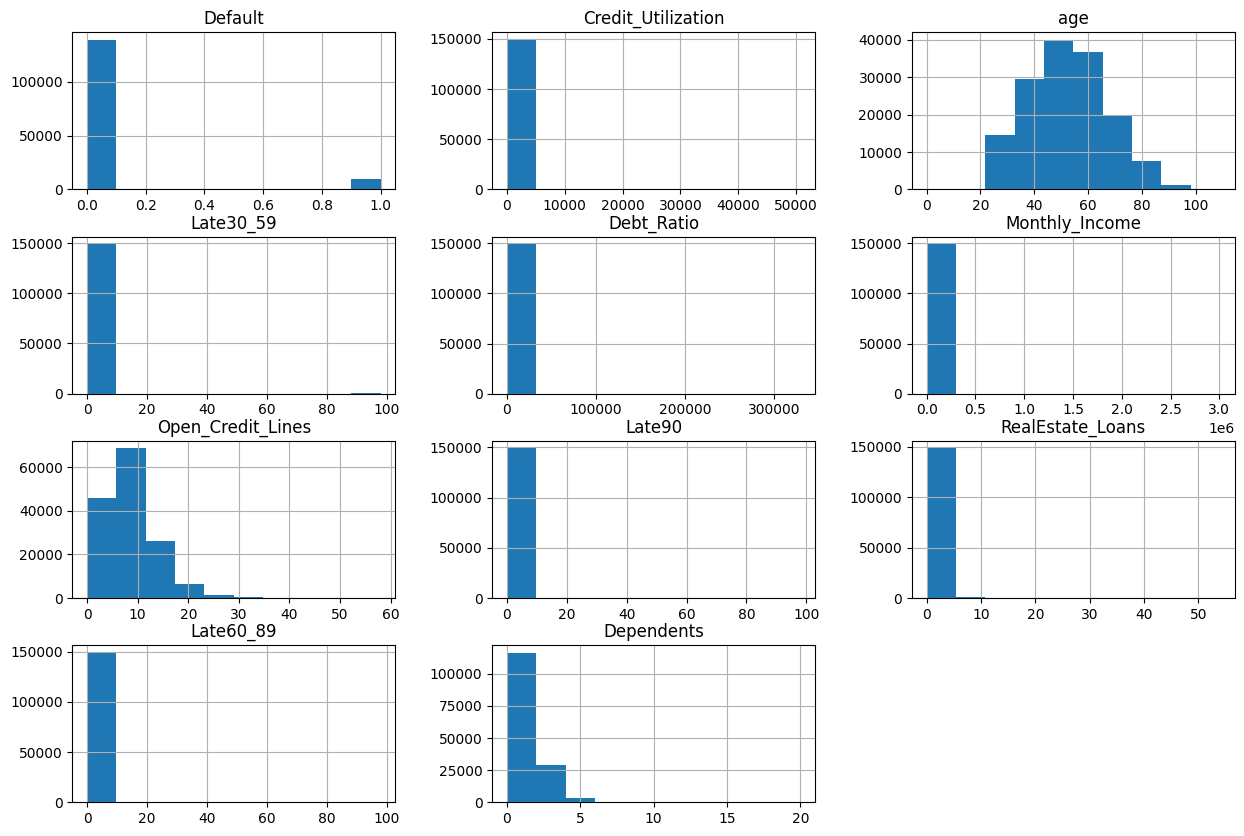

In [75]:
df.hist(figsize=(15,10))
plt.show()

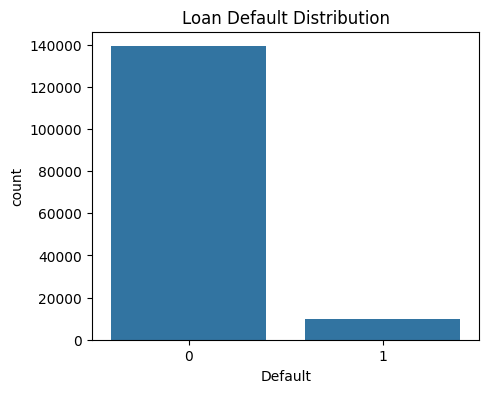

In [76]:
plt.figure(figsize=(5,4))
sns.countplot(x="Default", data=df)
plt.title("Loan Default Distribution")
plt.show()

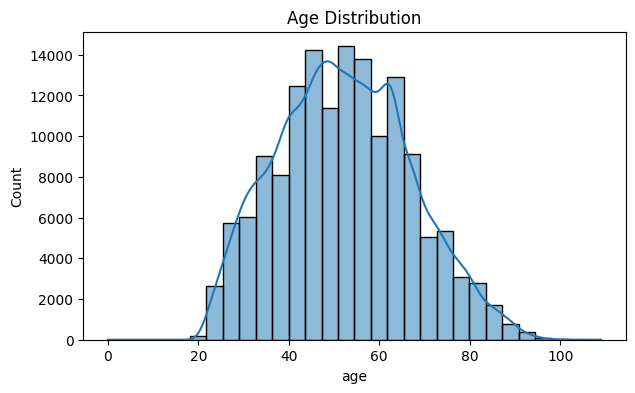

In [77]:
plt.figure(figsize=(7,4))
sns.histplot(df["age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

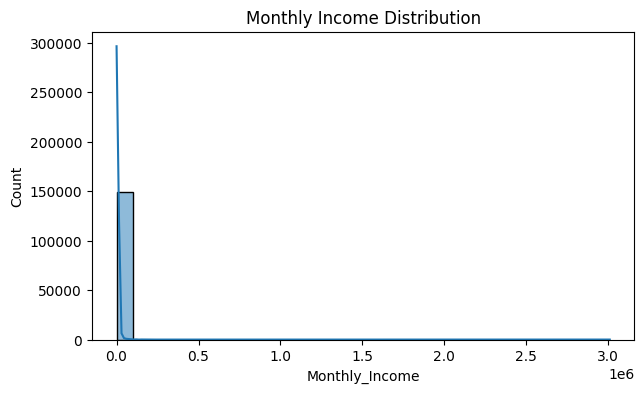

In [78]:
plt.figure(figsize=(7,4))
sns.histplot(df["Monthly_Income"], bins=30, kde=True)
plt.title("Monthly Income Distribution")
plt.show()

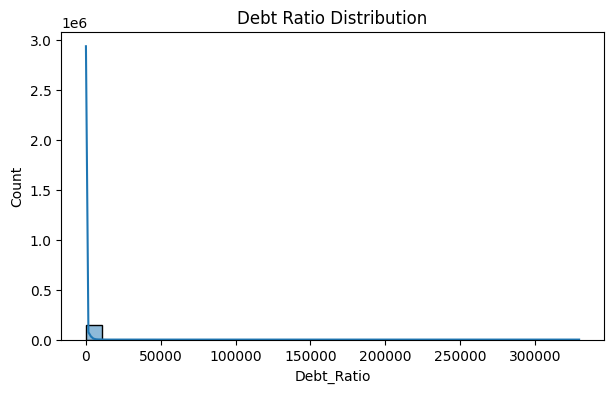

In [79]:
plt.figure(figsize=(7,4))
sns.histplot(df["Debt_Ratio"], bins=30, kde=True)
plt.title("Debt Ratio Distribution")
plt.show()

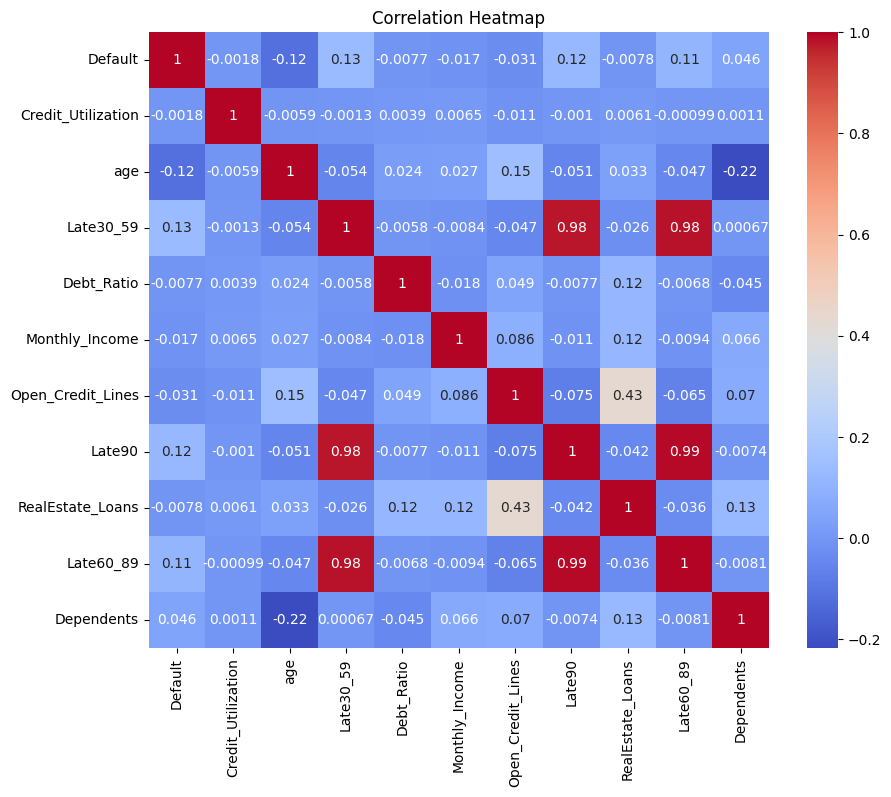

In [80]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

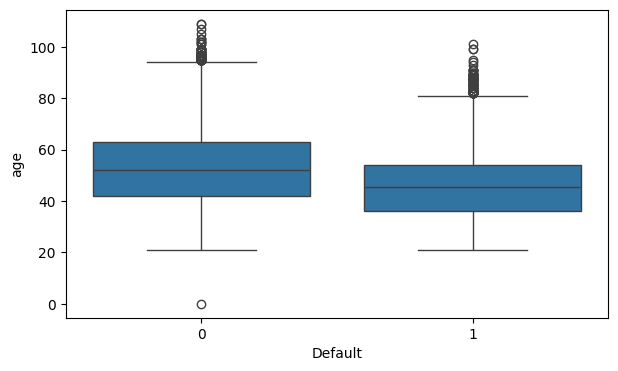

In [81]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Default", y="age", data=df)
plt.show()

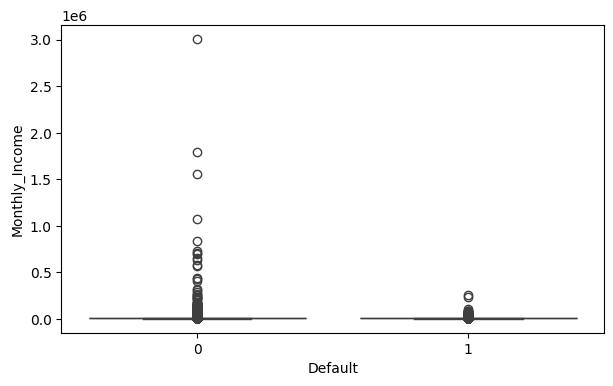

In [82]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Default", y="Monthly_Income", data=df)
plt.show()

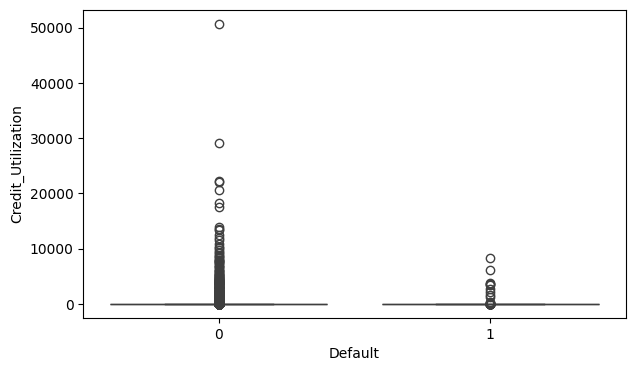

In [83]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Default", y="Credit_Utilization", data=df)
plt.show()

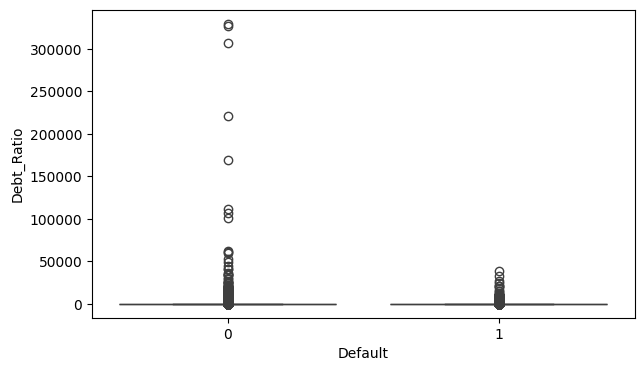

In [84]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Default", y="Debt_Ratio", data=df)
plt.show()

In [85]:
df["Age_Group"] = pd.cut(
    df["age"],
    bins=[20,30,40,50,60,100],
    labels=["21-30","31-40","41-50","51-60","60+"]
)

In [86]:
df["Age_Group"].value_counts()

,count
Age_Group,
60+,44725
41-50,34993
51-60,34707
31-40,24286
21-30,10508


In [87]:
df["Income_Group"] = pd.qcut(
    df["Monthly_Income"],
    q=4,
    labels=["Low","Medium","High","Very High"]
)

In [88]:
df["Income_Group"].value_counts()

,count
Income_Group,
Medium,51895
Low,37384
Very High,37306
High,22648


In [89]:
df["Credit_Utilization_Group"] = pd.cut(
    df["Credit_Utilization"],
    bins=[0,0.3,0.6,1,df["Credit_Utilization"].max()],
    labels=["Low","Medium","High","Very High"],
    include_lowest=True
)

In [90]:
df["Total_Late_Payments"] = (
    df["Late30_59"] +
    df["Late60_89"] +
    df["Late90"]
)

In [91]:
df["High_Debt"] = np.where(
    df["Debt_Ratio"]>1,
    1,
    0
)

In [92]:
df["High_Credit_Utilization"] = np.where(
    df["Credit_Utilization"]>0.8,
    1,
    0
)

In [93]:
df.head()

,Default,Credit_Utilization,age,Late30_59,Debt_Ratio,Monthly_Income,Open_Credit_Lines,Late90,RealEstate_Loans,Late60_89,Dependents,Age_Group,Income_Group,Credit_Utilization_Group,Total_Late_Payments,High_Debt,High_Credit_Utilization
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,41-50,Very High,High,2,0,0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,31-40,Low,High,0,0,1
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,31-40,Low,High,2,0,0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,21-30,Low,Low,0,0,0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,41-50,Very High,High,1,0,1


In [94]:
df.to_csv("credit_risk_feature_engineered.csv",index=False)

In [95]:
age_default = (
    df.groupby("Age_Group", observed=False)["Default"]
      .mean()
      .reset_index()
)

age_default["Default"] *= 100

age_default

,Age_Group,Default
0,21-30,11.714884
1,31-40,9.824590
2,41-50,8.267368
3,51-60,6.177428
4,60+,3.016210


In [96]:
income_default = (
    df.groupby("Income_Group", observed=False)["Default"]
      .mean()
      .reset_index()
)

income_default["Default"] *= 100

income_default

,Income_Group,Default
0,Low,9.073400
1,Medium,6.563253
2,High,6.358177
3,Very High,4.733823


In [97]:
df.groupby("High_Debt")["Default"].mean()*100

,Default
High_Debt,
0,6.760321
1,6.519387


In [98]:
df.groupby("High_Credit_Utilization")["Default"].mean()*100

,Default
High_Credit_Utilization,
0,3.798506
1,21.305981


In [99]:
df.groupby("Total_Late_Payments")["Default"].mean().head(15)

,Default
Total_Late_Payments,
0,0.027392
1,0.122178
2,0.240828
3,0.349636
4,0.426332
5,0.508511
6,0.584459
7,0.605263
8,0.598985


In [100]:
X = df.drop(
    columns=[
        "Default",
        "Age_Group",
        "Income_Group",
        "Credit_Utilization_Group"
    ]
)

y = df["Default"]

In [101]:
X.head()

,Credit_Utilization,age,Late30_59,Debt_Ratio,Monthly_Income,Open_Credit_Lines,Late90,RealEstate_Loans,Late60_89,Dependents,Total_Late_Payments,High_Debt,High_Credit_Utilization
0,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,2,0,0
1,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,0,1
2,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,2,0,0
3,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,0,0
4,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,1,0,1


In [102]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149233 entries, 0 to 149999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Credit_Utilization       149233 non-null  float64
 1   age                      149233 non-null  int64  
 2   Late30_59                149233 non-null  int64  
 3   Debt_Ratio               149233 non-null  float64
 4   Monthly_Income           149233 non-null  float64
 5   Open_Credit_Lines        149233 non-null  int64  
 6   Late90                   149233 non-null  int64  
 7   RealEstate_Loans         149233 non-null  int64  
 8   Late60_89                149233 non-null  int64  
 9   Dependents               149233 non-null  float64
 10  Total_Late_Payments      149233 non-null  int64  
 11  High_Debt                149233 non-null  int64  
 12  High_Credit_Utilization  149233 non-null  int64  
dtypes: float64(4), int64(9)
memory usage: 15.9 MB


In [103]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [104]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

y_prob_lr = lr.predict_proba(X_test)[:,1]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [105]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Logistic Regression")
print("----------------------------")
print("Accuracy :", accuracy_score(y_test,y_pred_lr))
print("Precision :", precision_score(y_test,y_pred_lr))
print("Recall :", recall_score(y_test,y_pred_lr))
print("F1 :", f1_score(y_test,y_pred_lr))
print("ROC AUC :", roc_auc_score(y_test,y_prob_lr))

Logistic Regression
----------------------------
Accuracy : 0.8178041344188696
Precision : 0.22358050506675245
Recall : 0.6946526736631684
F1 : 0.3382818203942565
ROC AUC : 0.8264692799043272


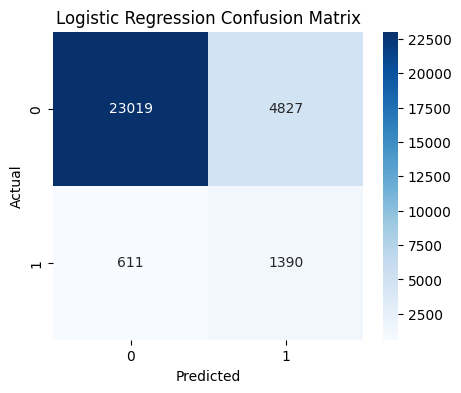

In [106]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pred_lr)

plt.figure(figsize=(5,4))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [107]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

           0       0.97      0.83      0.89     27846
           1       0.22      0.69      0.34      2001

    accuracy                           0.82     29847
   macro avg       0.60      0.76      0.62     29847
weighted avg       0.92      0.82      0.86     29847



In [108]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=20,
    random_state=42,
    class_weight="balanced"
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:,1]

In [109]:
print("Decision Tree")
print("----------------------------")

print("Accuracy :", accuracy_score(y_test,y_pred_dt))
print("Precision :", precision_score(y_test,y_pred_dt))
print("Recall :", recall_score(y_test,y_pred_dt))
print("F1 :", f1_score(y_test,y_pred_dt))
print("ROC AUC :", roc_auc_score(y_test,y_prob_dt))

Decision Tree
----------------------------
Accuracy : 0.8004489563440211
Precision : 0.21673112734565247
Recall : 0.7561219390304847
F1 : 0.3368960142507237
ROC AUC : 0.8530401537721408


In [110]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train,y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:,1]

In [111]:
print("Random Forest")
print("----------------------------")

print("Accuracy :", accuracy_score(y_test,y_pred_rf))
print("Precision :", precision_score(y_test,y_pred_rf))
print("Recall :", recall_score(y_test,y_pred_rf))
print("F1 :", f1_score(y_test,y_pred_rf))
print("ROC AUC :", roc_auc_score(y_test,y_prob_rf))

Random Forest
----------------------------
Accuracy : 0.8079874024190036
Precision : 0.22435707951522318
Recall : 0.7586206896551724
F1 : 0.3462986198243413
ROC AUC : 0.8604750451033192


In [112]:
comparison = pd.DataFrame({

"Model":[
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
],

"Accuracy":[
    accuracy_score(y_test,y_pred_lr),
    accuracy_score(y_test,y_pred_dt),
    accuracy_score(y_test,y_pred_rf)
],

"Precision":[
    precision_score(y_test,y_pred_lr),
    precision_score(y_test,y_pred_dt),
    precision_score(y_test,y_pred_rf)
],

"Recall":[
    recall_score(y_test,y_pred_lr),
    recall_score(y_test,y_pred_dt),
    recall_score(y_test,y_pred_rf)
],

"F1 Score":[
    f1_score(y_test,y_pred_lr),
    f1_score(y_test,y_pred_dt),
    f1_score(y_test,y_pred_rf)
],

"ROC AUC":[
    roc_auc_score(y_test,y_prob_lr),
    roc_auc_score(y_test,y_prob_dt),
    roc_auc_score(y_test,y_prob_rf)
]

})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.817804,0.223581,0.694653,0.338282,0.826469
1,Decision Tree,0.800449,0.216731,0.756122,0.336896,0.853040
2,Random Forest,0.807987,0.224357,0.758621,0.346299,0.860475


In [113]:
importance = pd.DataFrame({

"Feature":X.columns,

"Importance":rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
10,Total_Late_Payments,0.274268
0,Credit_Utilization,0.235924
6,Late90,0.111883
12,High_Credit_Utilization,0.111333
2,Late30_59,0.099723
8,Late60_89,0.053886
1,age,0.037277
3,Debt_Ratio,0.021302
5,Open_Credit_Lines,0.018139
4,Monthly_Income,0.015669


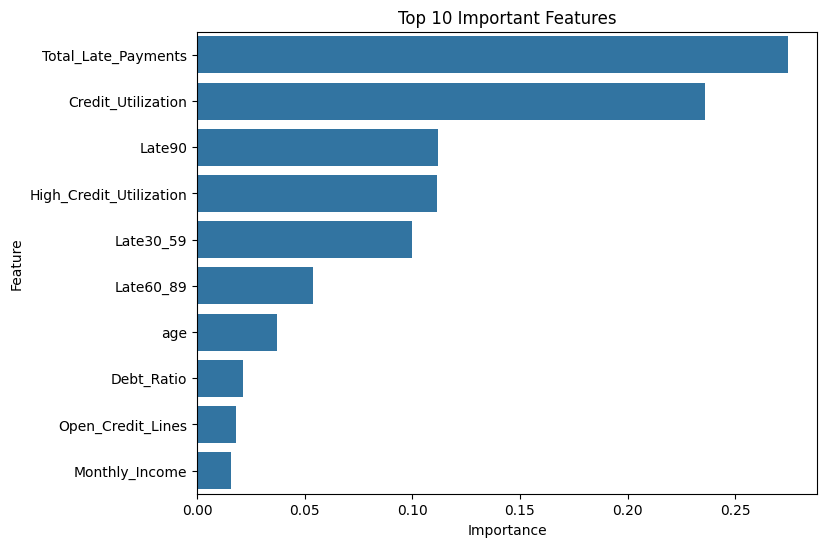

In [114]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.show()

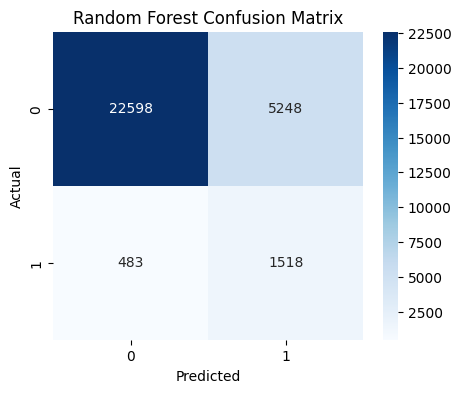

In [115]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [116]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.98      0.81      0.89     27846
           1       0.22      0.76      0.35      2001

    accuracy                           0.81     29847
   macro avg       0.60      0.79      0.62     29847
weighted avg       0.93      0.81      0.85     29847



In [117]:
importance = pd.DataFrame({

"Feature":X.columns,

"Importance":rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
10,Total_Late_Payments,0.274268
0,Credit_Utilization,0.235924
6,Late90,0.111883
12,High_Credit_Utilization,0.111333
2,Late30_59,0.099723
8,Late60_89,0.053886
1,age,0.037277
3,Debt_Ratio,0.021302
5,Open_Credit_Lines,0.018139
4,Monthly_Income,0.015669


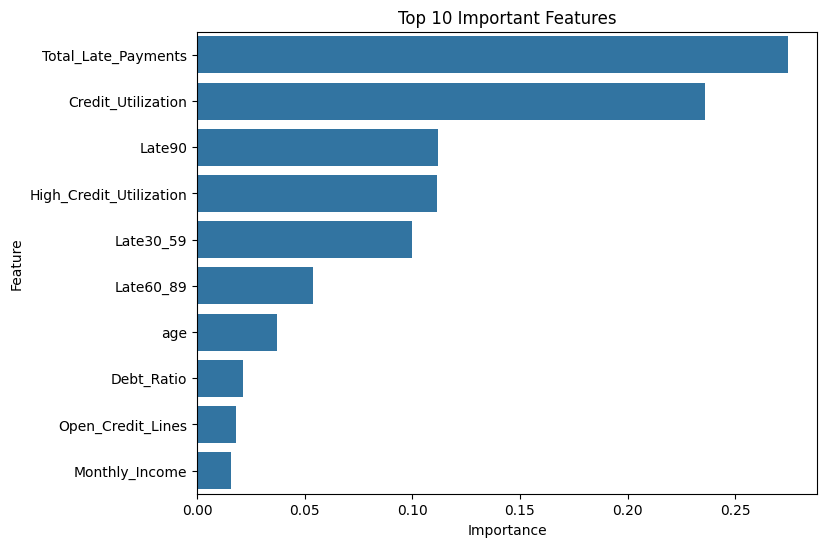

In [118]:
plt.figure(figsize=(8,6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")

plt.show()

In [119]:
predictions = X_test.copy()

predictions["Actual_Default"] = y_test.values

predictions["Predicted_Default"] = y_pred_rf

predictions["Risk_Probability"] = y_prob_rf

predictions.head()

,Credit_Utilization,age,Late30_59,Debt_Ratio,Monthly_Income,Open_Credit_Lines,Late90,RealEstate_Loans,Late60_89,Dependents,Total_Late_Payments,High_Debt,High_Credit_Utilization,Actual_Default,Predicted_Default,Risk_Probability
71427,0.085210,53,0,0.343154,7500.0,5,0,3,0,2.0,0,0,0,0,0,0.168738
140920,0.768854,30,0,783.000000,5400.0,7,0,0,0,2.0,0,1,0,0,0,0.481631
20505,1.000000,21,0,33.000000,5400.0,0,0,0,0,0.0,0,1,1,0,1,0.581098
705,0.046748,60,0,1.012369,3233.0,13,0,2,0,0.0,0,1,0,0,0,0.185633
10657,0.305379,45,0,0.426128,4500.0,6,0,1,0,2.0,0,0,0,0,0,0.241457


In [120]:
high_risk = predictions[
    predictions["Risk_Probability"] >= 0.70
]

high_risk.head()

,Credit_Utilization,age,Late30_59,Debt_Ratio,Monthly_Income,Open_Credit_Lines,Late90,RealEstate_Loans,Late60_89,Dependents,Total_Late_Payments,High_Debt,High_Credit_Utilization,Actual_Default,Predicted_Default,Risk_Probability
551,1.000000,63,3,0.200843,5217.0,5,0,1,1,4.0,4,0,1,0,1,0.871134
56455,0.995838,42,1,0.506258,4074.0,8,1,0,0,0.0,2,0,1,0,1,0.891725
50153,0.602655,30,1,0.094453,2000.0,5,0,0,1,0.0,2,0,0,0,1,0.779061
19935,0.881344,51,1,0.036126,9798.0,5,0,0,1,0.0,2,0,1,0,1,0.781352
84715,1.000000,31,1,0.255807,3400.0,4,2,0,1,3.0,4,0,1,0,1,0.947588


In [121]:
predictions.to_csv(
    "credit_risk_predictions.csv",
    index=False
)

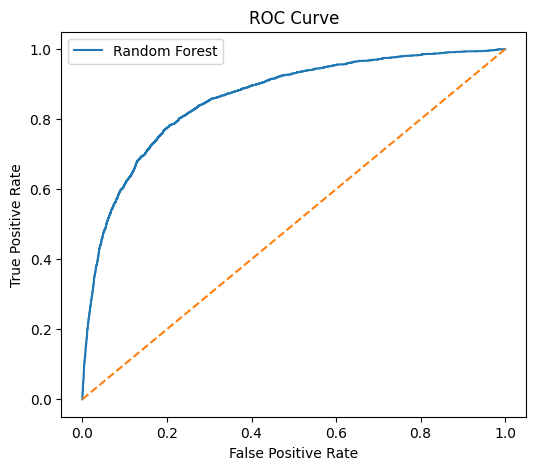

In [122]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    label="Random Forest"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

In [123]:
import sqlite3

conn = sqlite3.connect("credit_risk.db")

df.to_sql(
    "credit_risk",
    conn,
    if_exists="replace",
    index=False
)

149233

In [124]:
query = """

SELECT COUNT(*) AS Total_Customers
FROM credit_risk;

"""

pd.read_sql(query, conn)

,Total_Customers
0,149233


In [125]:
df.rename(columns={"Default":"Loan_Default"}, inplace=True)

In [126]:
import sqlite3

conn = sqlite3.connect("credit_risk.db")

df.to_sql(
    "credit_risk",
    conn,
    if_exists="replace",
    index=False
)

149233

In [127]:
pd.read_sql(

"PRAGMA table_info(credit_risk);",

conn
)

,cid,name,type,notnull,dflt_value,pk
0,0,Loan_Default,INTEGER,0,None,0
1,1,Credit_Utilization,REAL,0,None,0
2,2,age,INTEGER,0,None,0
3,3,Late30_59,INTEGER,0,None,0
4,4,Debt_Ratio,REAL,0,None,0
5,5,Monthly_Income,REAL,0,None,0
6,6,Open_Credit_Lines,INTEGER,0,None,0
7,7,Late90,INTEGER,0,None,0
8,8,RealEstate_Loans,INTEGER,0,None,0
9,9,Late60_89,INTEGER,0,None,0


In [128]:
query = """

SELECT
COUNT(*) AS Total_Defaulters

FROM credit_risk

WHERE Loan_Default = 1;

"""

pd.read_sql(query, conn)

,Total_Defaulters
0,10004


In [129]:
query = """

SELECT

ROUND(
100.0*SUM(Loan_Default)/COUNT(*),
2
)
AS Default_Rate

FROM credit_risk;

"""

pd.read_sql(query, conn)

,Default_Rate
0,6.7


In [130]:
query = """

SELECT

ROUND(
AVG(Monthly_Income),
2
)
AS Average_Income

FROM credit_risk;

"""

pd.read_sql(query, conn)

,Average_Income
0,6426.77


In [131]:
query = """

SELECT

ROUND(
AVG(Debt_Ratio),
2
)
AS Average_Debt_Ratio

FROM credit_risk;

"""

pd.read_sql(query, conn)

,Average_Debt_Ratio
0,354.81


In [132]:
query = """

SELECT

ROUND(
AVG(age),
0
)
AS Average_Age

FROM credit_risk;

"""

pd.read_sql(query, conn)

,Average_Age
0,52.0


In [133]:
query = """

SELECT

Age_Group,

COUNT(*) AS Customers,

SUM(Loan_Default) AS Defaulters,

ROUND(
100.0*SUM(Loan_Default)/COUNT(*),
2
)
AS Default_Rate

FROM credit_risk

GROUP BY Age_Group

ORDER BY Age_Group;

"""

pd.read_sql(query, conn)

,Age_Group,Customers,Defaulters,Default_Rate
0,None,14,1,7.14
1,21-30,10508,1231,11.71
2,31-40,24286,2386,9.82
3,41-50,34993,2893,8.27
4,51-60,34707,2144,6.18
5,60+,44725,1349,3.02


In [134]:
query = """

SELECT

Income_Group,

COUNT(*) AS Customers,

SUM(Loan_Default) AS Defaulters,

ROUND(
100.0*SUM(Loan_Default)/COUNT(*),
2
)
AS Default_Rate

FROM credit_risk

GROUP BY Income_Group;

"""

pd.read_sql(query, conn)

,Income_Group,Customers,Defaulters,Default_Rate
0,High,22648,1440,6.36
1,Low,37384,3392,9.07
2,Medium,51895,3406,6.56
3,Very High,37306,1766,4.73


In [135]:
query = """

SELECT

High_Debt,

COUNT(*) AS Customers

FROM credit_risk

GROUP BY High_Debt;

"""

pd.read_sql(query, conn)

,High_Debt,Customers
0,0,114107
1,1,35126


In [136]:
query = """

SELECT

High_Credit_Utilization,

COUNT(*) AS Customers

FROM credit_risk

GROUP BY High_Credit_Utilization;

"""

pd.read_sql(query, conn)

,High_Credit_Utilization,Customers
0,0,124470
1,1,24763


In [137]:
query = """

SELECT

Loan_Default,

ROUND(
AVG(Monthly_Income),
2
)
AS Average_Income

FROM credit_risk

GROUP BY Loan_Default;

"""

pd.read_sql(query, conn)

,Loan_Default,Average_Income
0,0,6486.63
1,1,5593.80


In [138]:
query = """

SELECT

Loan_Default,

ROUND(
AVG(Debt_Ratio),
2
)
AS Average_Debt

FROM credit_risk

GROUP BY Loan_Default;

"""

pd.read_sql(query, conn)

,Loan_Default,Average_Debt
0,0,359.05
1,1,295.77


In [139]:
query = """

SELECT

Loan_Default,

ROUND(
AVG(Credit_Utilization),
2
)
AS Average_Credit_Utilization

FROM credit_risk

GROUP BY Loan_Default;

"""

pd.read_sql(query, conn)

,Loan_Default,Average_Credit_Utilization
0,0,6.20
1,1,4.37


In [140]:
query = """

SELECT

age,

Monthly_Income,

Debt_Ratio,

Loan_Default

FROM credit_risk

ORDER BY Monthly_Income DESC

LIMIT 10;

"""

pd.read_sql(query, conn)

,age,Monthly_Income,Debt_Ratio,Loan_Default
0,52,3008750.0,0.001470,0
1,68,1794060.0,0.002776,0
2,44,1560100.0,0.004013,0
3,44,1072500.0,0.004537,0
4,55,835040.0,0.000147,0
5,67,730483.0,0.005570,0
6,50,702500.0,0.008268,0
7,52,699530.0,0.003698,0
8,49,649587.0,0.001313,0
9,83,629000.0,0.000000,0


In [141]:
query = """

SELECT

age,

Debt_Ratio,

Monthly_Income,

Loan_Default

FROM credit_risk

ORDER BY Debt_Ratio DESC

LIMIT 10;

"""

pd.read_sql(query, conn)

,age,Debt_Ratio,Monthly_Income,Loan_Default
0,65,329664.0,5400.0,0
1,65,326442.0,5400.0,0
2,58,307001.0,5400.0,0
3,37,220516.0,5400.0,0
4,56,168835.0,5400.0,0
5,71,110952.0,5400.0,0
6,65,106885.0,5400.0,0
7,66,101320.0,5400.0,0
8,63,61907.0,5400.0,0
9,89,61106.5,1.0,0


In [142]:
query = """

SELECT

CASE

WHEN Debt_Ratio < 0.5 THEN 'Low Risk'

WHEN Debt_Ratio BETWEEN 0.5 AND 1 THEN 'Medium Risk'

ELSE 'High Risk'

END AS Risk_Category,

COUNT(*) AS Customers

FROM credit_risk

GROUP BY Risk_Category;

"""

pd.read_sql(query, conn)

,Risk_Category,Customers
0,High Risk,35126
1,Low Risk,92952
2,Medium Risk,21155


In [143]:
query = """

SELECT

CASE

WHEN Monthly_Income < 3000 THEN 'Low Income'

WHEN Monthly_Income BETWEEN 3000 AND 7000 THEN 'Middle Income'

ELSE 'High Income'

END AS Income_Level,

COUNT(*) AS Customers,

SUM(Loan_Default) AS Defaulters,

ROUND(100.0*SUM(Loan_Default)/COUNT(*),2) AS Default_Rate

FROM credit_risk

GROUP BY Income_Level;

"""

pd.read_sql(query, conn)

,Income_Level,Customers,Defaulters,Default_Rate
0,High Income,40475,1962,4.85
1,Low Income,23229,2105,9.06
2,Middle Income,85529,5937,6.94


In [144]:
query = """

SELECT

Age_Group,

COUNT(*) Customers

FROM credit_risk

GROUP BY Age_Group

HAVING COUNT(*) > 10000;

"""

pd.read_sql(query, conn)

,Age_Group,Customers
0,21-30,10508
1,31-40,24286
2,41-50,34993
3,51-60,34707
4,60+,44725


In [145]:
query = """

SELECT

Income_Group,

AVG(Monthly_Income) Avg_Income

FROM credit_risk

GROUP BY Income_Group

ORDER BY Avg_Income DESC;

"""

pd.read_sql(query, conn)

,Income_Group,Avg_Income
0,Very High,12417.583981
1,High,6324.611886
2,Medium,5055.854071
3,Low,2413.412529


In [146]:
query = """

WITH Risk AS (

SELECT

age,

Monthly_Income,

Debt_Ratio,

Loan_Default

FROM credit_risk

)

SELECT

AVG(Monthly_Income) AS Avg_Income,

AVG(Debt_Ratio) AS Avg_Debt

FROM Risk

WHERE Loan_Default=1;

"""

pd.read_sql(query, conn)

,Avg_Income,Avg_Debt
0,5593.804178,295.767874


In [147]:
query = """

SELECT

age,

Monthly_Income,

RANK() OVER(

ORDER BY Monthly_Income DESC

) AS Income_Rank

FROM credit_risk

LIMIT 20;

"""

pd.read_sql(query, conn)

,age,Monthly_Income,Income_Rank
0,52,3008750.0,1
1,68,1794060.0,2
2,44,1560100.0,3
3,44,1072500.0,4
4,55,835040.0,5
5,67,730483.0,6
6,50,702500.0,7
7,52,699530.0,8
8,49,649587.0,9
9,83,629000.0,10


In [148]:
query = """

SELECT

age,

Debt_Ratio,

DENSE_RANK() OVER(

ORDER BY Debt_Ratio DESC

) AS Debt_Rank

FROM credit_risk

LIMIT 20;

"""

pd.read_sql(query, conn)

,age,Debt_Ratio,Debt_Rank
0,65,329664.0,1
1,65,326442.0,2
2,58,307001.0,3
3,37,220516.0,4
4,56,168835.0,5
5,71,110952.0,6
6,65,106885.0,7
7,66,101320.0,8
8,63,61907.0,9
9,89,61106.5,10


In [149]:
query = """

SELECT

age,

Monthly_Income,

ROW_NUMBER() OVER(

ORDER BY Monthly_Income DESC

) AS Row_Num

FROM credit_risk

LIMIT 20;

"""

pd.read_sql(query, conn)

,age,Monthly_Income,Row_Num
0,52,3008750.0,1
1,68,1794060.0,2
2,44,1560100.0,3
3,44,1072500.0,4
4,55,835040.0,5
5,67,730483.0,6
6,50,702500.0,7
7,52,699530.0,8
8,49,649587.0,9
9,83,629000.0,10


In [150]:
query = """

SELECT

age,

Monthly_Income,

Debt_Ratio,

Credit_Utilization,

Loan_Default

FROM credit_risk

ORDER BY Debt_Ratio DESC,

Credit_Utilization DESC

LIMIT 5;

"""

pd.read_sql(query, conn)

,age,Monthly_Income,Debt_Ratio,Credit_Utilization,Loan_Default
0,65,5400.0,329664.0,0.000000,0
1,65,5400.0,326442.0,0.001782,0
2,58,5400.0,307001.0,0.034290,0
3,37,5400.0,220516.0,0.182640,0
4,56,5400.0,168835.0,0.000000,0


In [151]:
query = """

SELECT

Age_Group,

ROUND(AVG(Monthly_Income),2) AS Avg_Income

FROM credit_risk

GROUP BY Age_Group

ORDER BY Avg_Income DESC;

"""

pd.read_sql(query, conn)

,Age_Group,Avg_Income
0,51-60,7291.75
1,41-50,7044.99
2,60+,6341.58
3,31-40,5695.21
4,None,4047.64
5,21-30,3567.62


In [152]:
query = """

SELECT

Total_Late_Payments,

COUNT(*) Customers,

SUM(Loan_Default) Defaulters

FROM credit_risk

GROUP BY Total_Late_Payments

ORDER BY Total_Late_Payments;

"""

pd.read_sql(query, conn)

,Total_Late_Payments,Customers,Defaulters
0,0,118938,3258
1,1,17229,2105
2,2,5942,1431
3,3,2883,1008
4,4,1595,680
5,5,940,478
6,6,592,346
7,7,380,230
8,8,197,118
9,9,125,84


In [153]:
query = """

SELECT

Open_Credit_Lines,

ROUND(AVG(Debt_Ratio),2) Avg_Debt

FROM credit_risk

GROUP BY Open_Credit_Lines

ORDER BY Avg_Debt DESC;

"""

pd.read_sql(query, conn)

,Open_Credit_Lines,Avg_Debt
0,34,978.74
1,43,900.59
2,33,775.83
3,25,749.93
4,26,742.65
5,35,656.10
6,29,648.73
7,27,641.66
8,24,631.20
9,28,625.20


In [154]:
query = """

SELECT

COUNT(*) AS Total_Customers,

SUM(Loan_Default) AS Total_Defaulters,

ROUND(100.0*SUM(Loan_Default)/COUNT(*),2) AS Default_Rate,

ROUND(AVG(Monthly_Income),2) AS Avg_Income,

ROUND(AVG(Debt_Ratio),2) AS Avg_Debt,

ROUND(AVG(Credit_Utilization),2) AS Avg_Credit_Utilization

FROM credit_risk;

"""

pd.read_sql(query, conn)

,Total_Customers,Total_Defaulters,Default_Rate,Avg_Income,Avg_Debt,Avg_Credit_Utilization
0,149233,10004,6.7,6426.77,354.81,6.08


In [155]:
df(credot_risk_cleaned)

NameError: name 'credot_risk_cleaned' is not defined

In [ ]:
df.rename(columns={

"SeriousDlqin2yrs":"Loan_Default",

"RevolvingUtilizationOfUnsecuredLines":"Credit_Utilization",

"age":"Age",

"NumberOfTime30-59DaysPastDueNotWorse":"Late30_59_Days",

"DebtRatio":"Debt_Ratio",

"MonthlyIncome":"Monthly_Income",

"NumberOfOpenCreditLinesAndLoans":"Open_Credit_Lines",

"NumberOfTimes90DaysLate":"Late90_Days",

"NumberRealEstateLoansOrLines":"RealEstate_Loans",

"NumberOfTime60-89DaysPastDueNotWorse":"Late60_89_Days",

"NumberOfDependents":"Dependents"

}, inplace=True)

In [156]:
df.rename(columns={

"SeriousDlqin2yrs":"Loan_Default",

"RevolvingUtilizationOfUnsecuredLines":"Credit_Utilization",

"age":"Age",

"NumberOfTime30-59DaysPastDueNotWorse":"Late30_59_Days",

"DebtRatio":"Debt_Ratio",

"MonthlyIncome":"Monthly_Income",

"NumberOfOpenCreditLinesAndLoans":"Open_Credit_Lines",

"NumberOfTimes90DaysLate":"Late90_Days",

"NumberRealEstateLoansOrLines":"RealEstate_Loans",

"NumberOfTime60-89DaysPastDueNotWorse":"Late60_89_Days",

"NumberOfDependents":"Dependents"

}, inplace=True)

In [157]:
df.to_csv("credit_risk_cleaned.csv", index=False)